## Financial Returns and Volatility

### Learning Goals
* Distinguish between simple returns and log returns in financial time series.
* Compute and visualize rolling volatility to observe time-varying dispersion.
* Understand why volatility measures dispersion (uncertainty) rather than directional expected return.

---

### 1. Prices and Log Returns

* **Simple Return:** $R_t = \frac{P_t - P_{t-1}}{P_{t-1}}$
* **Log Return:** $r_t = \log(P_t) - \log(P_{t-1})$

Log returns are mathematically additive across time and possess better statistical properties for modeling than raw price levels.

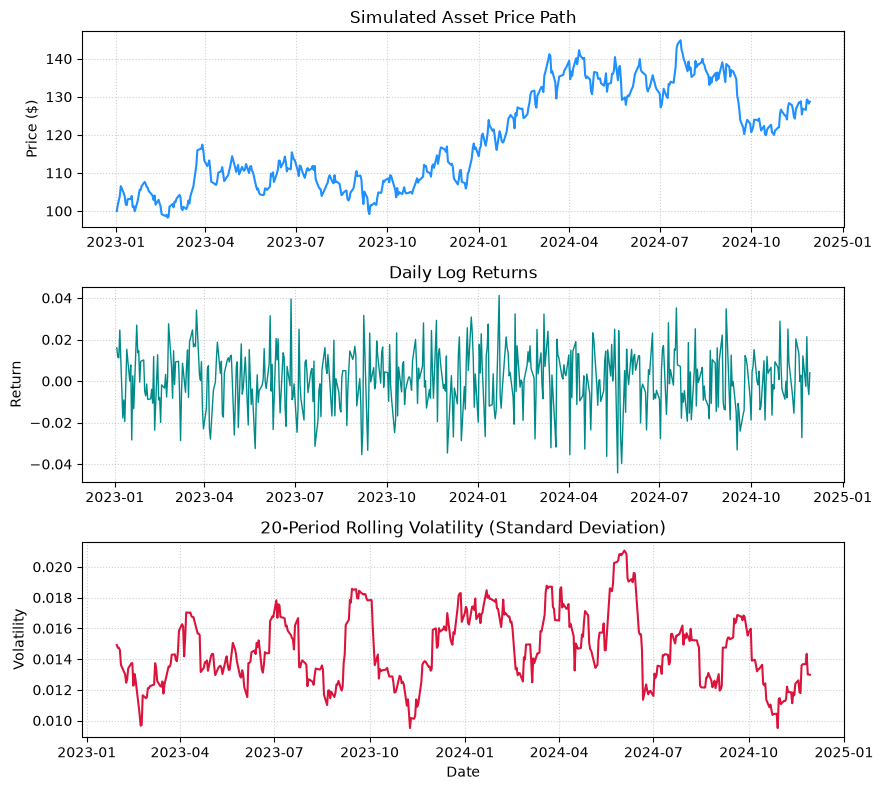

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(12)
n = 500
daily_returns = rng.normal(0.0003, 0.015, n)
prices = 100 * np.exp(np.cumsum(daily_returns))

dates = pd.date_range("2023-01-01", periods=n, freq="B")
price_series = pd.Series(prices, index=dates)
log_returns = np.log(price_series).diff().dropna()
rolling_volatility = log_returns.rolling(20).std()

fig, axes = plt.subplots(3, 1, figsize=(9, 8))

axes[0].plot(price_series, color='dodgerblue', linewidth=1.5)
axes[0].set_title("Simulated Asset Price Path")
axes[0].set_ylabel("Price ($)")
axes[0].grid(linestyle=':', alpha=0.6)

axes[1].plot(log_returns, color='darkcyan', linewidth=1.0)
axes[1].set_title("Daily Log Returns")
axes[1].set_ylabel("Return")
axes[1].grid(linestyle=':', alpha=0.6)

axes[2].plot(rolling_volatility, color='crimson', linewidth=1.5)
axes[2].set_title("20-Period Rolling Volatility (Standard Deviation)")
axes[2].set_ylabel("Volatility")
axes[2].set_xlabel("Date")
axes[2].grid(linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 2. Volatility vs. Expected Return

> **Key Distinction:** Volatility measures dispersion and uncertainty around the mean, not directional movement. A highly volatile asset can experience sharp surges as well as severe drawdowns.

---

### Exercises

Try each problem before running the verification code below:

1. Calculate annualized volatility from daily returns using standard convention ($\sigma_{\text{annual}} = \sigma_{\text{daily}} \times \sqrt{252}$).
2. Change the simulated daily volatility parameter and observe the visual impact on the rolling volatility plot.
3. Why does rolling volatility cluster and fluctuate over time in real financial markets?

In [2]:
# --- Exercise Verification & Explanations ---
print("=== Exercise Solutions & Checks ===")

# Exercise 1: Annualized Volatility Calculation
daily_std = log_returns.std()
annualized_vol = daily_std * np.sqrt(252)

print(f"\n1. Volatility Metrics:")
print(f"   - Daily Volatility (SD):     {daily_std:.4f}")
print(f"   - Annualized Volatility (252 trading days): {annualized_vol:.4f}")

print("\n2. Changing Daily Volatility:")
print("   - Increasing daily volatility scales the magnitude of returns and shifts the")
print("     baseline level of the rolling volatility chart upward.")

print("\n3. Why Volatility Clusters Over Time:")
print("   - Financial markets exhibit volatility clustering (periods of high turbulence followed")
print("     by periods of relative calm), captured by models like ARCH/GARCH.")

=== Exercise Solutions & Checks ===

1. Volatility Metrics:
   - Daily Volatility (SD):     0.0147
   - Annualized Volatility (252 trading days): 0.2329

2. Changing Daily Volatility:
   - Increasing daily volatility scales the magnitude of returns and shifts the
     baseline level of the rolling volatility chart upward.

3. Why Volatility Clusters Over Time:
   - Financial markets exhibit volatility clustering (periods of high turbulence followed
     by periods of relative calm), captured by models like ARCH/GARCH.
